# 06 — Does the relationship survive a harder test?

The EDA found raw correlations of 0.5–0.8 between PM2.5 and search in Bangkok and Kraków. It also found two reasons not to trust them yet:

- **Shared seasonality.** Both series peak in the same months, so they would correlate even if nobody searched *because of* pollution.
- **Autocorrelation.** Neighbouring weeks are not independent, so ordinary p-values overstate the evidence.

This notebook addresses both, for every usable search series.

| Problem | What is done here |
|---|---|
| Shared seasonality | A seasonal fit (trend + annual sine waves) is subtracted from both series; the residuals are correlated |
| Autocorrelation in the interval | Block bootstrap: weeks are resampled in 8-week blocks |
| Autocorrelation in the p-value | Circular-shift test: one series is slid against the other, which keeps each series' persistence but breaks the pairing |
| Many tests at once | Benjamini–Hochberg adjustment across all 21 tests |
| Skewed data | Rank-based (Kruskal–Wallis) comparison across pollution levels |

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import awareness as A, features as F, plots as P, stats as S
from aqs.config import CITIES, PROCESSED

pd.set_option("display.precision", 3)
P.use_theme()
long = F.load_long()

## 1. Raw against deseasonalised correlation

The seasonal fit is a regression on a linear trend and three annual sine/cosine pairs. Unlike STL it is fitted only to weeks that exist, so it needs no interpolation across the gaps in the PM2.5 record and works for Melbourne too.

In [2]:
table = S.correlation_table(long)
table.to_csv(PROCESSED / "results_summary.csv", index=False)
table

,city,series,weeks,raw_r,raw_spearman,deseason_r,ci_low,ci_high,p_shift,peak_lag,p_fdr,significant
0,bangkok,attention index (PC1),150,0.702,0.819,0.528,0.370,0.660,0.007,0,0.011,True
1,bangkok,"air purifier (English, country)",150,0.575,0.730,0.327,0.114,0.557,0.007,0,0.011,True
2,bangkok,"air quality (English, country)",150,0.653,0.770,0.549,0.392,0.684,0.007,0,0.011,True
3,bangkok,"air purifier (English, region)",150,0.634,0.664,0.444,0.286,0.571,0.007,0,0.011,True
4,bangkok,air purifier (Thai),150,0.604,0.688,0.381,0.156,0.574,0.007,0,0.011,True
5,bangkok,"air quality (English, region)",150,0.760,0.777,0.650,0.540,0.730,0.007,0,0.011,True
6,bangkok,air quality (Thai),150,0.504,0.454,0.296,0.117,0.480,0.007,0,0.011,True
7,bangkok,dust (Thai),150,0.659,0.755,0.511,0.363,0.642,0.007,0,0.011,True
8,bangkok,PM2.5 (Thai usage),150,0.747,0.823,0.607,0.498,0.709,0.007,0,0.011,True
9,krakow,attention index (PC1),134,0.745,0.697,0.582,0.338,0.708,0.007,0,0.011,True


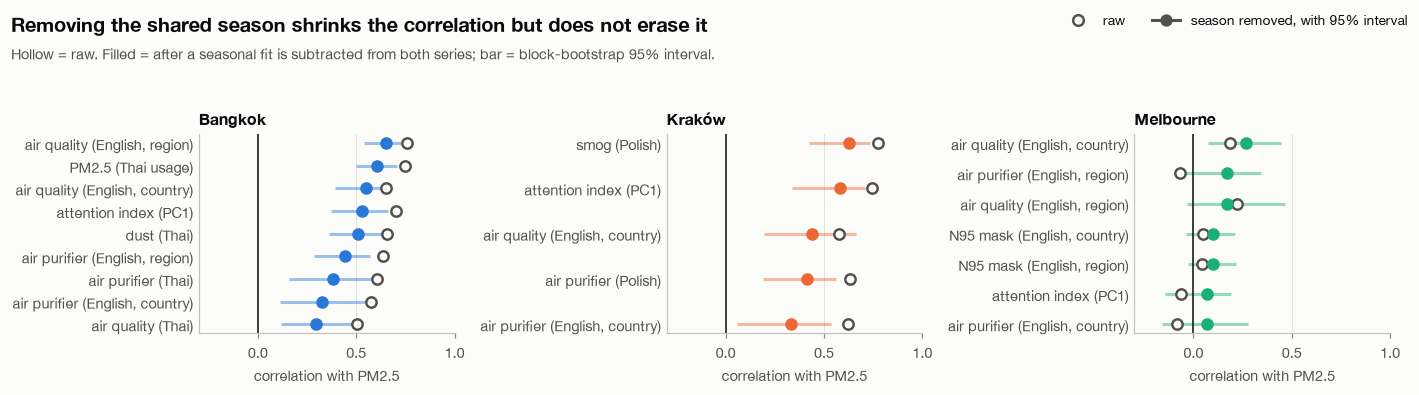

In [3]:
P.raw_vs_deseasonalized(table);

**Reading it.** Removing the season pulls every Bangkok and Kraków correlation down, as it should: part of the raw figure was the shared calendar. But none of them falls to zero. The attention index keeps a correlation of about 0.5 in Bangkok and 0.6 in Kraków, and every interval in those two cities stays clear of zero. In Melbourne nothing survives the multiple-comparison adjustment.

This changes one conclusion from the first iteration of the project, which described Kraków's search as driven by the heating-season calendar rather than by PM2.5. With the weeks aligned and local-language terms, Kraków's response to pollution survives removal of the season.

A limit of the shift test: with about 135 possible shifts, the smallest p-value it can return is 0.007. Every Bangkok and Kraków series sits at that floor.

## 2. Lead and lag once the season is gone

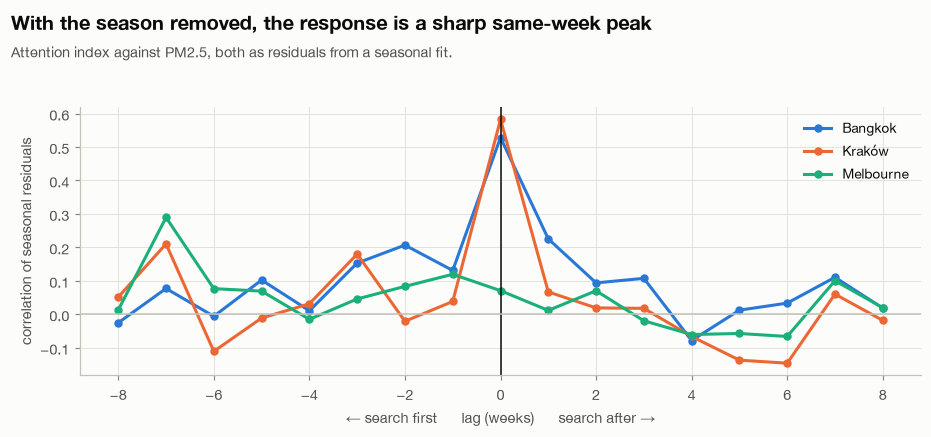

In [4]:
P.deseasonalized_lags(long);

**Reading it.** In the EDA the lag curves were broad humps, because the season kept the correlation high for weeks either side. With the season removed, Bangkok and Kraków show a single sharp peak at lag zero and little either side. Search responds within the week and does not anticipate pollution.

## 3. Does attention differ across pollution levels?

Weeks are split into the lowest, middle and highest third of each city's own PM2.5, and the attention index is compared across the three groups with a Kruskal–Wallis test. Epsilon-squared is the share of rank variance explained by the grouping.

In [5]:
pd.DataFrame({c: S.tertile_test(F.attention_pair(long, c)) for c in CITIES}).T

,H,p,epsilon_sq,median_low,median_mid,median_high
bangkok,87.092,1.225e-19,0.579,-0.631,-0.302,0.256
krakow,64.565,9.547e-15,0.478,-0.688,-0.409,0.723
melbourne,0.079,9.613e-01,-0.021,-0.219,-0.165,-0.177


**Reading it.** In Bangkok and Kraków median attention rises step by step from the least to the most polluted third, and the grouping explains roughly half of the rank variance. In Melbourne the three groups are indistinguishable.

## Summary

| City | Raw correlation (attention index) | Season removed | Verdict |
|---|---|---|---|
| Bangkok | 0.70 | 0.53 (95% interval 0.37–0.66) | Relationship survives |
| Kraków | 0.75 | 0.58 (0.34–0.71) | Relationship survives |
| Melbourne | −0.06 | 0.07 (−0.15–0.19) | No relationship |

The full table is saved to `data/processed/results_summary.csv`.